# 24 — Vector Fields on Graphs, Graph Laplacians, and Graph Fourier Analysis

**Primary source:** Borde & Bronstein, *Mathematical Foundations of Geometric Deep Learning*, §7.3, [arXiv:2508.02723](https://arxiv.org/abs/2508.02723).

**Expanded sources:** Shuman et al., *The Emerging Field of Signal Processing on Graphs* ([arXiv:1211.0053](https://arxiv.org/abs/1211.0053)); Ortega et al., *Graph Signal Processing: Overview, Challenges and Applications* ([arXiv:1712.00468](https://arxiv.org/abs/1712.00468)); Chung, *Spectral Graph Theory*.

**Goals.** Build the Laplacian from local differences, derive its energy and spectral properties, construct the graph Fourier transform, and use the theory to understand smoothing and graph neural networks. We work with finite, undirected graphs and nonnegative symmetric weights unless stated otherwise.

**Convention.** Every undirected edge is counted **once** in sums over $E$. This avoids the frequent factor-of-two ambiguity in graph Dirichlet energy.

## 1. Node-feature fields (§7.3)

Let $G=(V,E,w)$ have $n$ vertices and weights $w_{ij}=w_{ji}\geq0$. A **graph signal** (scalar field on vertices) is a map

$$f:V\to\mathbb R,\qquad f(v_i)=f_i.$$

A **node-feature field** is $F:V\to\mathbb R^d$, recorded as a matrix $X\in\mathbb R^{n\times d}$ with $i$-th row $x_i^\top$. This is the usage of *vector field on graphs* in the primary source: vectors are feature vectors attached to nodes, not necessarily tangent vectors or edge flows.

**Example:** temperatures at sensors form a scalar graph signal; three measured chemical concentrations at each sensor form a 3-channel node-feature field.

**Non-example:** assigning a single number to every *edge* is an edge signal (a discrete 1-cochain), not a vertex signal. A vector in $\mathbb R^3$ attached to a node need not be a geometric tangent vector.

A relabelling of vertices by permutation matrix $P$ gives $X'=PX$ and $A'=PAP^\top$. An equivariant vertex operator $T$ satisfies $T(PX;PAP^\top)=PT(X;A)$. In contrast, sum/mean/max pooling over vertices is permutation **invariant**.

## 2. Adjacency, degree, and Laplacian

For a weighted graph, the **adjacency (weight) matrix** is $A_{ij}=w_{ij}$ for edges and $0$ otherwise. The **weighted degree** of $v_i$ is

$$d_i=\sum_j A_{ij},\qquad D=\operatorname{diag}(d_1,\ldots,d_n).$$

The **combinatorial Laplacian** is

$$\boxed{L=D-A.}$$

Acting on a vertex signal,

$$\boxed{(Lf)_i=\sum_j w_{ij}(f_i-f_j).}$$

This is a *difference operator*: it compares a value to neighbouring values. For an unweighted graph, $d_i$ is the number of neighbours.

**Example: Computing the graph Laplacian of a vertex signal**

Consider the path graph

$$
1 \longrightarrow 2 \longrightarrow 3,
$$

where the arrows merely indicate the order of the vertices; the graph is undirected.

Its adjacency and degree matrices are

$$
A=
\begin{pmatrix}
0&1&0\\
1&0&1\\
0&1&0
\end{pmatrix},
\qquad
D=
\begin{pmatrix}
1&0&0\\
0&2&0\\
0&0&1
\end{pmatrix}.
$$

Therefore, the combinatorial graph Laplacian is

$$
L=D-A=
\begin{pmatrix}
1&-1&0\\
-1&2&-1\\
0&-1&1
\end{pmatrix}.
$$

Now consider a scalar-valued function $f:V\to\mathbb R$ defined by

$$
f(1)=1,\qquad f(2)=3,\qquad f(3)=2.
$$

We represent this function as the vector

$$
f=
\begin{pmatrix}
1\\
3\\
2
\end{pmatrix}.
$$

**Computing $Lf$ using matrix multiplication**

$$
\begin{aligned}
Lf
&=
\begin{pmatrix}
1&-1&0\\
-1&2&-1\\
0&-1&1
\end{pmatrix}
\begin{pmatrix}
1\\
3\\
2
\end{pmatrix}\\[6pt]
&=
\begin{pmatrix}
1-3\\
-1+6-2\\
-3+2
\end{pmatrix}\\[6pt]
&=
\boxed{
\begin{pmatrix}
-2\\
3\\
-1
\end{pmatrix}
}.
\end{aligned}
$$

**Computing $Lf$ using neighbouring differences**

Recall that, for an unweighted graph,

$$
(Lf)_i=\sum_{j\sim i}(f_i-f_j).
$$

We can compute the Laplacian at each vertex separately.

- **Vertex 1:** Its only neighbour is vertex 2.

  $$
  (Lf)_1=f(1)-f(2)=1-3=-2.
  $$

- **Vertex 2:** Its neighbours are vertices 1 and 3.

  $$
  \begin{aligned}
  (Lf)_2
  &=(f(2)-f(1))+(f(2)-f(3))\\
  &=(3-1)+(3-2)=3.
  \end{aligned}
  $$

- **Vertex 3:** Its only neighbour is vertex 2.

  $$
  (Lf)_3=f(3)-f(2)=2-3=-1.
  $$

Thus, we recover

$$
\boxed{
Lf=
\begin{pmatrix}
-2\\
3\\
-1
\end{pmatrix}.
}
$$

**Interpretation**

The graph Laplacian measures how a vertex's value differs from those of its neighbours.

For a vertex of positive degree,

$$
(Lf)_i=d_i\left(f_i-\frac{1}{d_i}\sum_{j\sim i}f_j\right).
$$

Thus:

- $(Lf)_1=-2$: The value at vertex 1 is smaller than its neighbour's value.
- $(Lf)_2=3$: The value at vertex 2 is larger than the average of its neighbours' values.
- $(Lf)_3=-1$: The value at vertex 3 is smaller than its neighbour's value.

Notice that

$$
\sum_{i=1}^3(Lf)_i=-2+3-1=0.
$$

This is not a coincidence. For every undirected graph,

$$
\mathbf 1^\top Lf=0,
$$

because $L\mathbf 1=0$ and $L$ is symmetric.

**Exercise 1:** Repeat the calculation for the constant function

$$
f=
\begin{pmatrix}
2\\
2\\
2
\end{pmatrix}.
$$

What do you observe? Explain why the graph Laplacian of every constant function is zero.

**Exercise: Graph Laplacian of a two-dimensional vector-valued field**

Consider the same path graph

$$
1-2-3
$$

with graph Laplacian

$$
L=
\begin{pmatrix}
1&-1&0\\
-1&2&-1\\
0&-1&1
\end{pmatrix}.
$$

Suppose that each vertex is assigned a two-dimensional feature vector, defining a vector-valued field

$$
f:V\longrightarrow\mathbb R^2
$$

given by

$$
f(1)=
\begin{pmatrix}
1\\2
\end{pmatrix},
\qquad
f(2)=
\begin{pmatrix}
3\\1
\end{pmatrix},
\qquad
f(3)=
\begin{pmatrix}
2\\4
\end{pmatrix}.
$$

We represent this field by the feature matrix

$$
F=
\begin{pmatrix}
1&2\\
3&1\\
2&4
\end{pmatrix}
\in\mathbb R^{3\times 2},
$$

where each row corresponds to a vertex and each column corresponds to a feature.

The graph Laplacian acts independently on each feature dimension:

$$
\boxed{
LF=
\begin{pmatrix}
1&-1&0\\
-1&2&-1\\
0&-1&1
\end{pmatrix}
\begin{pmatrix}
1&2\\
3&1\\
2&4
\end{pmatrix}.
}
$$

**Questions**

1. Compute $LF$ using matrix multiplication.

2. Verify your answer using the neighbouring-difference formula

   $$
   (Lf)(i)=\sum_{j\sim i}\big(f(i)-f(j)\big),
   $$

   where the differences are now vectors in $\mathbb R^2$.

3. Verify that the sum of the resulting vectors is zero:

   $$
   \sum_{i=1}^3(Lf)(i)=
   \begin{pmatrix}
   0\\0
   \end{pmatrix}.
   $$

4. Compute the graph Dirichlet energy

   $$
   E(F)=\frac12\operatorname{tr}(F^\top LF).
   $$

   Verify that it can also be written as

   $$
   E(F)=\frac12\sum_{\{i,j\}\in E}
   \|f(i)-f(j)\|^2.
   $$

5. Explain why the graph Laplacian acts on the **vertex dimension** of $F$, rather than mixing its two feature dimensions.

**Remark:** Here, a vector-valued field simply assigns an element of $\mathbb R^2$ to each vertex. It does not necessarily represent a geometric tangent vector field, which would require additional geometric structure.

**Subtlety:** self-loops contribute equally to $D$ and $A$, hence cancel in $D-A$. Later, GCNs deliberately add self-loops to the *normalized propagation* operator.

### Experiment 1 — Construct a graph and inspect its matrices

We use NetworkX only to build and draw the graph; the linear-algebra calculations are performed explicitly with NumPy.

A =
 [[0. 1. 0.]
 [1. 0. 1.]
 [0. 1. 0.]] 
D =
 [[1. 0. 0.]
 [0. 2. 0.]
 [0. 0. 1.]] 
L =
 [[ 1. -1.  0.]
 [-1.  2. -1.]
 [ 0. -1.  1.]]


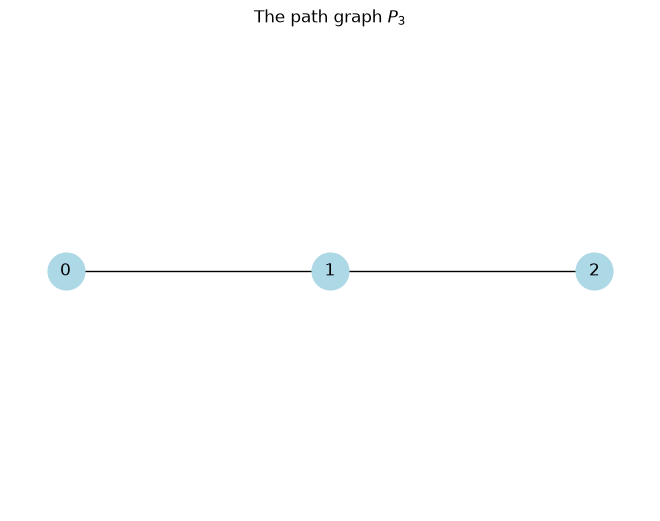

In [1]:
# Import numerical arrays and linear algebra.
import numpy as np
# Import graph construction and visualization tools.
import networkx as nx
# Import plotting tools.
import matplotlib.pyplot as plt
# Set a consistent numerical print format.
np.set_printoptions(precision=3, suppress=True)
# Build an undirected path with three vertices.
G = nx.path_graph(3)
# Convert the adjacency matrix into a dense NumPy array.
A = nx.to_numpy_array(G, nodelist=range(3))
# Compute each vertex degree by summing adjacency rows.
degrees = A.sum(axis=1)
# Put the degrees on the diagonal.
D = np.diag(degrees)
# Construct the combinatorial graph Laplacian.
L = D - A
# Display all three matrices.
print("A =\n", A, "\nD =\n", D, "\nL =\n", L)
# Check that constant signals are annihilated.
assert np.allclose(L @ np.ones(3), 0)
# Draw the graph with a reproducible layout.
nx.draw(G, pos={0:(0,0),1:(1,0),2:(2,0)}, with_labels=True, node_color="lightblue", node_size=700)
# Add a descriptive title.
plt.title("The path graph $P_3$")
# Show the figure.
plt.show()

## 3. The discrete gradient, incidence matrix, and integration by parts

Choose an **arbitrary orientation** for each undirected edge $e=(i\to j)$, solely to define signs. Let $B\in\mathbb R^{m\times n}$ be the oriented incidence matrix: row $e$ has $-1$ at $i$, $+1$ at $j$, and zero elsewhere. Then

$$\boxed{(Bf)_e=f_j-f_i}$$

is the **discrete gradient** of a vertex signal. Let $W=\operatorname{diag}(w_e)$ and define the weighted edge inner product $\langle p,q\rangle_W=p^\top Wq$. The adjoint of $B$ relative to the standard vertex inner product and this weighted edge inner product is $B^\top W$. Therefore

$$\boxed{L=B^\top WB.}$$

The identity

$$\langle f,Lg\rangle=\langle Bf,Bg\rangle_W$$

is the graph analogue of integration by parts (with our sign convention, $L$ is a **positive** Laplacian, analogous to $-\Delta$ in the common PDE convention).

**Orientation independence:** reversing an edge changes the sign of one row of $B$ but leaves $B^\top WB$ unchanged.

**Example:** on $P_3$, orient edges $1\to2$ and $2\to3$. Then $B=\begin{pmatrix}-1&1&0\\0&-1&1\end{pmatrix}$.

## 4. Graph Dirichlet energy: definition and derivation

Define the **graph Dirichlet energy** by

$$\boxed{\mathcal E(f)=\frac12\sum_{\{i,j\}\in E}w_{ij}(f_i-f_j)^2=\frac12 f^\top Lf.}$$

Here each undirected edge appears once. If instead we sum over *all ordered pairs* $(i,j)$, then

$$f^\top Lf=\frac12\sum_{i,j}w_{ij}(f_i-f_j)^2.$$

**Derivation:**

$$\begin{aligned}f^\top Lf&=\sum_i d_i f_i^2-\sum_{i,j}w_{ij}f_if_j\\&=\frac12\sum_{i,j}w_{ij}(f_i^2+f_j^2-2f_if_j)\\&=\sum_{\{i,j\}\in E}w_{ij}(f_i-f_j)^2.\end{aligned}$$

Equivalently, $2\mathcal E(f)=\|W^{1/2}Bf\|_2^2$.

**Interpretation:** small energy means the signal varies little along heavily weighted edges. This is graph *smoothness*, not smoothness in a Euclidean embedding.

**Example:** on $P_3$, $f=(2,2,2)$ has zero energy, while $g=(0,1,0)$ has $\mathcal E(g)=1$.

**Non-example:** a rapidly changing signal across two vertices with **no connecting edge** incurs no direct energy penalty.

**Vector-valued extension:** for $X\in\mathbb R^{n\times d}$, $\mathcal E(X)=\frac12\operatorname{tr}(X^\top LX)=\frac12\sum_{\{i,j\}\in E}w_{ij}\|x_i-x_j\|^2$. This assumes all feature vectors are expressed in the same $\mathbb R^d$; gauge-valued geometric fields may require parallel transport before comparison.

## 5. Variational interpretation and harmonic extension

The first variation of the Dirichlet energy is

$$\mathcal E(f+\varepsilon h)=\mathcal E(f)+\varepsilon h^\top Lf+O(\varepsilon^2),\qquad\boxed{\nabla_f\mathcal E=Lf.}$$

Therefore, unconstrained minimizers are constant on each connected component. With boundary vertices $S$ held fixed, minimizing over interior vertices $I$ yields

$$L_{II}f_I=-L_{IS}f_S.$$

This is the discrete **Dirichlet problem**. At an interior vertex of positive degree, $(Lf)_i=0$ is equivalent to

$$f_i=\frac{\sum_j w_{ij}f_j}{d_i},$$

so a harmonic signal equals the weighted average of its neighbours.

**Example:** on a three-vertex path, fixing endpoint values $0$ and $2$ makes the energy-minimizing middle value $1$.

### Experiment 2 — Verify the energy identities and harmonic extension

We check the incidence-factorization formula numerically, compare two graph signals, and solve a boundary-value problem.

In [2]:
# Choose an orientation for the two path edges.
B = np.array([[-1., 1., 0.], [0., -1., 1.]])
# Use unit weights for both edges.
W = np.eye(2)
# Verify that the incidence construction recovers the Laplacian.
assert np.allclose(B.T @ W @ B, L)
# Define a constant signal.
f_constant = np.array([2., 2., 2.])
# Define a signal with a sharp change.
f_spike = np.array([0., 1., 0.])
# Define the Dirichlet energy from its quadratic form.
def energy(f, laplacian):
    # Return one half of the graph Laplacian quadratic form.
    return 0.5 * float(f @ laplacian @ f)
# Compare the energies of the two signals.
print("Constant energy:", energy(f_constant, L))
# Display the energy of the spike signal.
print("Spike energy:", energy(f_spike, L))
# Verify the equivalent edge-gradient formula.
assert np.isclose(2 * energy(f_spike, L), np.sum((B @ f_spike) ** 2))
# Fix the first and last values of a harmonic signal.
f_boundary = np.array([0., 2.])
# Select the middle vertex as the interior.
interior = [1]
# Select the endpoints as boundary vertices.
boundary = [0, 2]
# Solve the discrete Dirichlet equation for the interior value.
f_middle = np.linalg.solve(L[np.ix_(interior, interior)], -L[np.ix_(interior, boundary)] @ f_boundary)
# Display the expected midpoint value.
print("Harmonic midpoint:", f_middle)
# Check the predicted harmonic interpolation.
assert np.allclose(f_middle, [1.])

Constant energy: 0.0
Spike energy: 1.0
Harmonic midpoint: [1.]


## 6. Fundamental spectral properties

Because $L=B^\top WB$, the Laplacian is **symmetric positive semidefinite**:

$$f^\top Lf=\sum_{\{i,j\}\in E}w_{ij}(f_i-f_j)^2\geq0.$$

The spectral theorem therefore gives orthonormal eigenvectors $u_0,\ldots,u_{n-1}$ with

$$Lu_k=\lambda_k u_k,\quad 0=\lambda_0\leq\lambda_1\leq\cdots\leq\lambda_{n-1},\quad L=U\Lambda U^\top.$$

**Kernel theorem:** $Lf=0$ iff $f$ is constant on each connected component (assuming graph edges have positive weight). Thus

$$\boxed{\dim\ker L=\text{number of connected components}.}$$

For a connected graph, $u_0=\mathbf1/\sqrt n$. The smallest positive eigenvalue $\lambda_1$ is the **spectral gap** or **algebraic connectivity** (often called $\lambda_2$ with one-based indexing).

**Rayleigh quotient:** for $f\ne0$,

$$R(f)=\frac{f^\top Lf}{f^\top f}=\frac{\sum_{\{i,j\}\in E}w_{ij}(f_i-f_j)^2}{\sum_i f_i^2}.$$

For connected graphs, $\lambda_1=\min_{f\perp\mathbf1,\ f\ne0}R(f)$. The minimizing vector is a **Fiedler vector**. Its sign is arbitrary; when eigenvalues repeat, an eigenbasis inside the eigenspace is not canonical.

**Example:** $P_3$ has eigenvalues $0,1,3$.

**Non-example:** the smallest eigenvalue of a combinatorial Laplacian cannot be negative for nonnegative symmetric edge weights.

## 7. What does graph frequency mean?

For a Laplacian eigenvector $u_k$ normalized to $\|u_k\|_2=1$,

$$\boxed{u_k^\top Lu_k=\lambda_k.}$$

Thus the eigenvalue **is its total edge variation**. Small eigenvalues correspond to smooth modes; large eigenvalues correspond to modes that oscillate strongly *across graph edges*. Unlike classical Fourier analysis, there need not be a spatial coordinate or a translation group.

The phrase *frequency* is therefore defined relative to the graph and the chosen Laplacian. Two graphs on the same vertices can assign different frequency content to the same signal.

**Example:** the alternating signal on an even cycle is a high-frequency Laplacian eigenvector.

**Non-example:** large numerical values of a signal do not imply high graph frequency: a constant signal of magnitude $10^6$ still has zero Dirichlet energy.

### Experiment 3 — Visualize eigenmodes and their graph variation

The first eigenvectors of a path graph behave like discrete smooth-to-oscillatory modes. We display them as signals indexed by the path vertices.

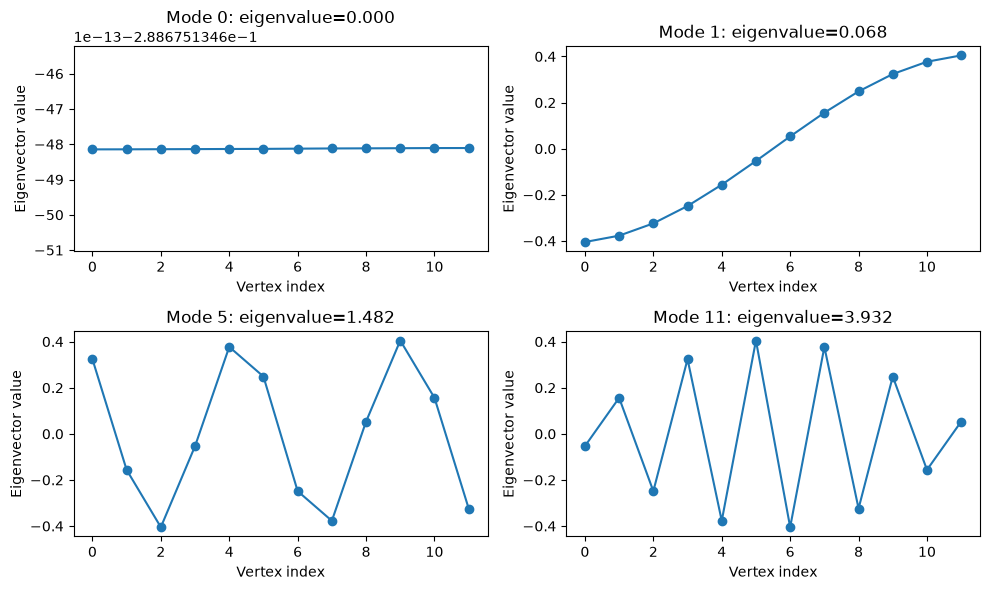

In [3]:
# Build a path graph with twelve vertices.
G_path = nx.path_graph(12)
# Compute its adjacency matrix.
A_path = nx.to_numpy_array(G_path)
# Compute the path Laplacian.
L_path = np.diag(A_path.sum(axis=1)) - A_path
# Compute its ordered eigenvalues and orthonormal eigenvectors.
eigenvalues, U = np.linalg.eigh(L_path)
# Create a figure for four eigenmodes.
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
# Choose representative low- and high-frequency modes.
indices = [0, 1, 5, 11]
# Iterate over the four selected modes.
for ax, k in zip(axes.flat, indices):
    # Plot eigenvector components along the path vertices.
    ax.plot(range(12), U[:, k], marker="o")
    # Display the eigenvalue and graph Dirichlet energy.
    ax.set_title(f"Mode {k}: eigenvalue={eigenvalues[k]:.3f}")
    # Label the horizontal axis.
    ax.set_xlabel("Vertex index")
    # Label the vertical axis.
    ax.set_ylabel("Eigenvector value")
# Avoid overlap between figure elements.
plt.tight_layout()
# Display the four modes.
plt.show()
# Check that each mode's quadratic variation equals its eigenvalue.
assert np.allclose(np.diag(U.T @ L_path @ U), eigenvalues)

## 8. Normalized Laplacians

For vertices with positive degree, the **symmetric normalized Laplacian** is

$$\boxed{L_{\mathrm{sym}}=I-D^{-1/2}AD^{-1/2}=D^{-1/2}LD^{-1/2}.}$$

The **random-walk Laplacian** is

$$\boxed{L_{\mathrm{rw}}=I-D^{-1}A=D^{-1}L.}$$

They are similar on graphs with no isolated vertices: $L_{\mathrm{sym}}=D^{1/2}L_{\mathrm{rw}}D^{-1/2}$, hence have the same eigenvalues. Unlike $L_{\mathrm{sym}}$, $L_{\mathrm{rw}}$ is generally not symmetric in the standard Euclidean inner product.

For any vector $z$,

$$z^\top L_{\mathrm{sym}}z=\sum_{\{i,j\}\in E}w_{ij}\left(\frac{z_i}{\sqrt{d_i}}-\frac{z_j}{\sqrt{d_j}}\right)^2.$$

The normalized spectrum lies in $[0,2]$. For a connected graph, $L_{\mathrm{sym}}D^{1/2}\mathbf1=0$; the zero eigenvector is generally **not constant**. The value $2$ is an eigenvalue of a connected graph exactly when it is bipartite.

**Isolated vertices:** define $D^{-1/2}_{ii}=0$ when $d_i=0$ and use $L_{\mathrm{sym}}=D^{-1/2}LD^{-1/2}$. This gives a zero row for each isolated vertex. Writing $I-D^{-1/2}AD^{-1/2}$ without adjustment instead gives a diagonal $1$ there, so the two expressions cease to agree. Our experiments avoid isolated vertices.

**Non-example:** substituting $D^{-1}A$ for $D^{-1/2}AD^{-1/2}$ does not generally produce a symmetric matrix.

## 9. Graph Fourier transform (GFT)

Fix a symmetric Laplacian $L=U\Lambda U^\top$, with columns $u_k$. The **graph Fourier transform** of $f\in\mathbb R^n$ is

$$\boxed{\widehat f=U^\top f,\qquad \widehat f_k=\langle u_k,f\rangle.}$$

Its **inverse** is

$$\boxed{f=U\widehat f=\sum_k\widehat f_k u_k.}$$

By orthogonality, the graph analogue of **Parseval's identity** is

$$\|f\|_2^2=\sum_k|\widehat f_k|^2.$$

More importantly, Dirichlet energy is diagonal in the Fourier basis:

$$\boxed{2\mathcal E(f)=f^\top Lf=\sum_k\lambda_k|\widehat f_k|^2.}$$

Thus high-frequency coefficients are penalized more strongly by smoothness regularization.

**Example:** for connected $G$, a constant signal has Fourier support only in the zero eigenspace.

**Non-example:** the coefficients $\widehat f_k$ are not intrinsically ordered when eigenvalues repeat: the basis of a degenerate eigenspace may rotate. The *projection onto that eigenspace* is intrinsic.

For a multichannel signal $X\in\mathbb R^{n\times d}$, the transform acts along the vertex dimension: $\widehat X=U^\top X$.

### Experiment 4 — Graph Fourier decomposition and Parseval identities

We construct a signal from a smooth mode and an oscillatory mode, inspect its spectrum, and reconstruct it exactly.

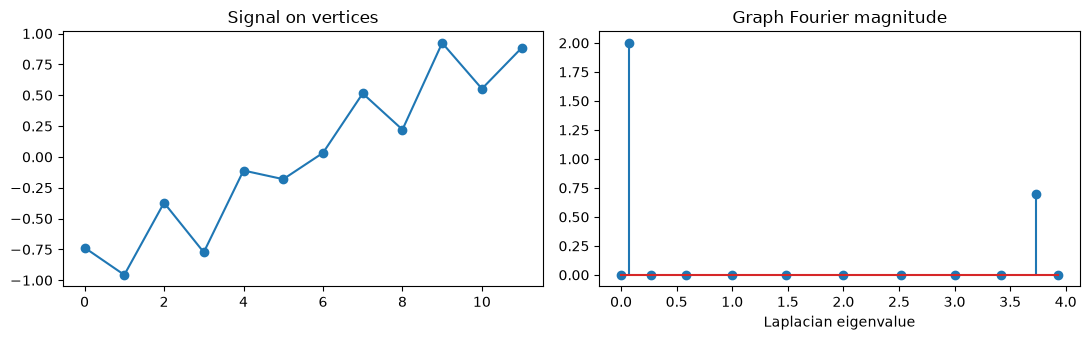

In [4]:
# Combine one low-frequency and one high-frequency eigenmode.
f = 2.0 * U[:, 1] + 0.7 * U[:, 10]
# Compute graph Fourier coefficients using the eigenbasis.
f_hat = U.T @ f
# Reconstruct the signal with the inverse graph Fourier transform.
f_reconstructed = U @ f_hat
# Check exact reconstruction to numerical precision.
assert np.allclose(f, f_reconstructed)
# Check preservation of Euclidean signal energy.
assert np.isclose(np.sum(f ** 2), np.sum(f_hat ** 2))
# Check the frequency-domain expression for Dirichlet energy.
assert np.isclose(f @ L_path @ f, np.sum(eigenvalues * f_hat ** 2))
# Create two panels for vertex and frequency representations.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
# Plot the signal in the vertex domain.
axes[0].plot(f, marker="o")
# Label the vertex-domain plot.
axes[0].set_title("Signal on vertices")
# Plot Fourier coefficient magnitudes against graph eigenvalues.
axes[1].stem(eigenvalues, np.abs(f_hat))
# Label the spectral plot.
axes[1].set_title("Graph Fourier magnitude")
# Label the spectral horizontal axis.
axes[1].set_xlabel("Laplacian eigenvalue")
# Improve panel spacing.
plt.tight_layout()
# Show the Fourier experiment.
plt.show()

## 10. Spectral graph filters and diffusion

A **spectral filter** with response $h:[0,\infty)\to\mathbb R$ acts as

$$\boxed{h(L)f=Uh(\Lambda)U^\top f,\quad h(\Lambda)=\operatorname{diag}(h(\lambda_k)).}$$

Its Fourier coefficients satisfy $\widehat{h(L)f}_k=h(\lambda_k)\widehat f_k$.

- **Low-pass:** $h(\lambda)$ decreases with $\lambda$ (smooths signals).
- **High-pass:** $h(0)=0$ and larger responses at larger eigenvalues (emphasizes variation).
- **Polynomial filter:** $h(L)=\sum_{r=0}^K a_rL^r$; a degree-$K$ polynomial is $K$-hop localized because $L$ only couples adjacent vertices.

The **heat equation on a graph** is

$$\frac{df}{dt}=-Lf,\qquad\boxed{f(t)=e^{-tL}f(0)}.$$

Its spectral response is $h_t(\lambda)=e^{-t\lambda}$: high-frequency components decay fastest. Along the flow,

$$\frac{d}{dt}\frac12\|f(t)\|^2=-f(t)^\top Lf(t)\leq0.$$

For a connected graph, $f(t)$ converges to the constant vector with the original mean. On a disconnected graph, it converges to the componentwise means.

**Non-example:** a graph spectral filter is not generally translation-invariant in a Euclidean sense; graph domains usually have no global translations.

### Experiment 5 — Heat diffusion smooths a graph signal

We evolve a spike on a path using the exact spectral heat operator, then monitor the Dirichlet energy and the mean.

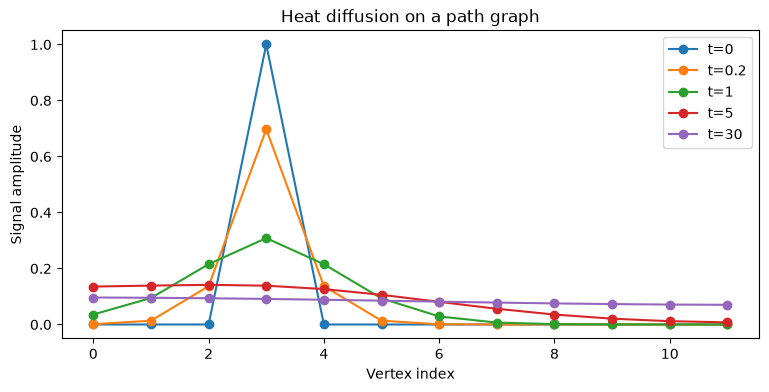

Dirichlet energies: [1.    0.33  0.028 0.001 0.   ]


In [5]:
# Initialize a spike at one vertex of the path.
f0 = np.zeros(12)
# Give the spike a unit amplitude.
f0[3] = 1.0
# Choose diffusion times including the initial state.
times = [0.0, 0.2, 1.0, 5.0, 30.0]
# Create a figure for the diffusion trajectories.
fig, ax = plt.subplots(figsize=(9, 4))
# Initialize a list of graph energies.
energies = []
# Iterate over the requested diffusion times.
for t in times:
    # Apply the heat response to each Fourier coefficient.
    f_t = U @ (np.exp(-t * eigenvalues) * (U.T @ f0))
    # Record the graph Dirichlet energy at this time.
    energies.append(energy(f_t, L_path))
    # Plot the diffused signal across the path vertices.
    ax.plot(f_t, marker="o", label=f"t={t:g}")
    # Check that the vertex mean is conserved.
    assert np.isclose(f_t.mean(), f0.mean())
# Label the diffusion plot.
ax.set_title("Heat diffusion on a path graph")
# Label the horizontal axis.
ax.set_xlabel("Vertex index")
# Label the vertical axis.
ax.set_ylabel("Signal amplitude")
# Display the diffusion times.
ax.legend()
# Display the figure.
plt.show()
# Verify that Dirichlet energy decreases along the heat flow.
assert np.all(np.diff(energies) <= 1e-10)
# Print the observed Dirichlet energies.
print("Dirichlet energies:", np.round(energies, 6))

## 11. From spectral theory to geometric deep learning

**Spectral convolution.** A learnable spectral multiplier $h_\theta(\lambda)$ produces $Y=h_\theta(L)X$. Its exact eigenbasis implementation is expensive on large graphs and requires care across changing graph structures. Polynomial approximations avoid computing eigenvectors and are spatially localized.

**GCN propagation.** Standard GCNs commonly use

$$\widetilde A=A+I,\quad \widetilde D_{ii}=\sum_j\widetilde A_{ij},\qquad H^{(\ell+1)}=\sigma\!\left(\widetilde D^{-1/2}\widetilde A\widetilde D^{-1/2}H^{(\ell)}W_\ell\right).$$

This is a degree-normalized, self-loop-augmented neighbourhood aggregation operator. It is related to spectral filtering, but should **not** be identified with the heat operator $e^{-tL}$ or an arbitrary Laplacian spectral filter.

**Permutation equivariance.** Under $A'=PAP^\top$ and $X'=PX$, we have $L'=PLP^\top$, so any polynomial or well-defined spectral function obeys $h(L')X'=Ph(L)X$.

**Oversmoothing.** Repeated low-pass propagation can suppress differences between node representations. The precise limit depends on the propagation operator, graph connectivity, self-loops, nonlinearities, and learned weights.

**Laplacian positional encodings.** Low nontrivial eigenvectors can encode graph structure, but individual eigenvectors are not canonical: sign flips and rotations within repeated eigenspaces must be handled. An equivariant implementation must not assume a unique basis.

**Gauge connection.** Node-feature fields $V\to\mathbb R^d$ use a common coordinate feature space. If node features live in different geometric fibres, subtracting $x_i-x_j$ may be meaningless without transport; a connection-aware Laplacian replaces ordinary differences with transported differences.

## 12. Further spectral insights

**(a) Connectedness and zero modes.** The dimension of the zero-frequency subspace is exactly the number of connected components. Thus spectral analysis detects connectivity without explicitly traversing edges.

**(b) Spectral gap and smoothing.** If $G$ is connected and $f\perp\mathbf1$, then $f^\top Lf\geq\lambda_1\|f\|^2$. Consequently, $\|e^{-tL}f\|\leq e^{-t\lambda_1}\|f\|$. A larger spectral gap implies faster decay of mean-zero modes under continuous-time diffusion.

**(c) The normalized Rayleigh quotient.** With no isolated vertices,

$$\frac{z^\top L_{\mathrm{sym}}z}{z^\top z}=\frac{\sum_{\{i,j\}\in E}w_{ij}(f_i-f_j)^2}{\sum_i d_i f_i^2},\quad z=D^{1/2}f.$$

This explains the degree-weighted geometry underlying normalized spectral analysis.

**(d) Graphs versus manifolds.** On a compact Riemannian manifold, Laplace–Beltrami eigenfunctions form a Fourier-like basis; on a graph, Laplacian eigenvectors do the analogous job. Convergence of graph Laplacians to differential operators requires careful sampling, weighting, and rescaling assumptions; it does not hold for arbitrary graph sequences.

## 13. Exercises

1. **Example/non-example:** Give two vertex signals on a fixed graph with identical Euclidean norms but different Dirichlet energies. Give a graph signal with large norm and zero energy.
2. Compute $A,D,L$ for the star $K_{1,4}$; verify that $L\mathbf1=0$.
3. Prove $L=B^\top WB$ for any orientation of a weighted undirected graph.
4. Prove that the graph Dirichlet energy is independent of edge orientation.
5. For the path $P_4$, compute the energy of $(0,1,1,0)$ by both edge differences and the quadratic form.
6. Derive $\nabla_f\mathcal E=Lf$ and solve the discrete Dirichlet problem on $P_4$ with endpoint values $0$ and $3$.
7. Prove that the multiplicity of eigenvalue zero equals the number of connected components.
8. Derive the Rayleigh quotient characterization of the spectral gap for a connected graph.
9. Find all eigenvalues of $P_3$ and verify that the eigenvector energies equal their eigenvalues.
10. Derive the symmetric normalized Laplacian quadratic form; explain why its zero eigenvector is not generally constant.
11. Compute the GFT of a constant signal and of an alternating signal on the cycle $C_4$.
12. Prove Parseval's identity and $f^\top Lf=\sum_k\lambda_k|\widehat f_k|^2$.
13. Show that $e^{-tL}$ preserves the sum of vertex values and reduces Dirichlet energy.
14. Prove permutation equivariance of a polynomial graph filter.
15. Investigate the sign ambiguity of Laplacian eigenvectors and the additional ambiguity when an eigenvalue is repeated.
16. **Experiment:** Compare heat diffusion on a path, cycle, and complete graph with the same number of vertices; relate convergence to spectral gaps.
17. **Research extension:** Construct a transport-aware Dirichlet energy for vectors living in different fibres and derive its associated connection Laplacian.

**Suggested practice:** Attempt exercises 1–5 before modifying the computational cells. For exercises 7–15, first prove the claim symbolically, then test it numerically.

## 14. References and reading guide

**Primary sequence**

1. Borde & Bronstein, *Mathematical Foundations of Geometric Deep Learning*, §7.3, [arXiv:2508.02723](https://arxiv.org/abs/2508.02723). The original section introduces node-feature fields, permutation behaviour, graph Laplacians, Dirichlet energy, normalized Laplacians, and graph Fourier analysis. We preserve that conceptual order while expanding proofs and experiments.

**Supplementary material used for the expansions**

2. Shuman, Narang, Frossard, Ortega & Vandergheynst, *The Emerging Field of Signal Processing on Graphs*, [arXiv:1211.0053](https://arxiv.org/abs/1211.0053). Graph Fourier analysis, spectral notions of frequency, filtering, and graph signal processing.
3. Ortega, Frossard, Kovačević, Moura & Vandergheynst, *Graph Signal Processing: Overview, Challenges and Applications*, [arXiv:1712.00468](https://arxiv.org/abs/1712.00468). Further graph signal processing context.
4. Fan Chung, *Spectral Graph Theory*, CBMS Regional Conference Series, 1997. Normalized Laplacians, eigenvalues, and connectivity.
5. Kipf & Welling, *Semi-Supervised Classification with Graph Convolutional Networks*, [arXiv:1609.02907](https://arxiv.org/abs/1609.02907). The normalized propagation operator used in GCNs.

**Scope note.** We focus on symmetric, nonnegative, undirected graphs. Directed, signed, magnetic, and connection Laplacians require separate definitions and may not share all the same properties.